# Fraud ranking across a short transaction timeline

How much fraud can a small review queue recover, and how does that answer change when evaluation follows transaction time? This study uses the original ULB/Worldline European credit-card data distributed as OpenML dataset 1597. The observations cover two days in September 2013. Labels describe recorded fraud, not every form of financial anomaly.

The questions are whether a nonlinear model improves ranking over logistic regression, how class weighting changes probability quality, and how validation-selected alert thresholds transfer to a later period. Average precision (AP) is the primary ranking measure. ROC-AUC, calibration, alert volume, and missed frauds provide complementary evidence. AP is a step-weighted summary of the precision-recall curve; it is not trapezoidal PR area.

IEEE-CIS was the preferred source. This environment had no Kaggle credentials or confirmed competition access, so no competition files were downloaded. The alternative has genuine labels and relative time but lacks the richer IEEE-CIS identity and transaction fields. It also has a much shorter observation window. No synthetic benchmark observations or invented calendar dates are used.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             roc_curve, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from transaction_anomaly.creditcard import (read_creditcard, split_creditcard, FEATURES,
                                          experiment, summarize)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEED = 42
started = time.monotonic()
source = ROOT / 'data/creditcard.parquet'
manifest = json.loads((ROOT / 'data/manifest.json').read_text())
assert hashlib.sha256(source.read_bytes()).hexdigest() == manifest['sha256']
assert len(source.read_bytes()) == 73231184
frame = read_creditcard(source)
assert len(frame) == 284807 and int(frame.Class.sum()) == 492
environment = {'python': platform.python_version(), 'packages': {p: metadata.version(p)
               for p in ['numpy','pandas','scikit-learn','scipy','matplotlib','pyarrow']}, 'threads': 4}
display(pd.Series(environment['packages'], name='version'))
display(pd.Series(manifest))
print('Rows:', len(frame), 'frauds:', int(frame.Class.sum()), 'columns:', len(frame.columns))


numpy            2.5.4
pandas           2.3.3
scikit-learn     1.9.1
scipy           1.18.1
matplotlib      3.11.2
pyarrow         26.0.0
Name: version, dtype: object

source_url          https://data.openml.org/datasets/0000/1597/dat...
metadata_url             https://www.openml.org/api/v1/json/data/1597
bytes                                                        73231184
sha256              b7efcb35a428bbe22347a05d2437d9177bab07ce61e512...
retrieved_at_utc                     2026-10-31T22:31:45.661224+00:00
format                                                 OpenML Parquet
license_metadata                                               Public
dtype: object

Rows: 284807 frauds: 492 columns: 31


## Source, rights, and observation units

[OpenML metadata](https://www.openml.org/api/v1/json/data/1597) identifies the authors as Andrea Dal Pozzolo, Olivier Caelen, and Gianluca Bontempi, and describes the Worldline and ULB research collaboration. The [original ULB Kaggle listing](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) reports database and database-contents terms; its public API labels them "Database: Open Database, Contents: Database Contents". OpenML itself records only "Public", which is less specific. OpenML's published Parquet distribution is used because the ARFF transfer stalled. The Parquet download is checked against its complete HTTP length, original schema, documented cohort counts, and locally recorded SHA-256. OpenML's ARFF MD5 does not apply to these Parquet bytes. These checks identify bytes; they do not independently establish the uploader's authority.

Required citation: Dal Pozzolo, Caelen, Johnson, and Bontempi, *Calibrating Probability with Undersampling for Unbalanced Classification*, IEEE CIDM, 2015. Original records, model objects, and individual predictions remain local. This report publishes aggregate analysis only.

`Time` gives seconds since the first transaction. `Amount` is an original numeric amount field; no currency conversion is attempted. `V1` to `V28` are anonymized PCA components. Their original variables, transformation fitting cohort, cardholder identities, and label arrival times are unavailable. A training-only scaler cannot undo possible information sharing in upstream PCA. The data cannot support customer-disjoint validation or a prospective delayed-chargeback simulation.

## Cohort audit and chronological protocol

Boundaries are fixed at 103,680 and 138,240 elapsed seconds, corresponding to 60% and 80% of a nominal 48-hour window. Transactions before the first boundary train models; the next interval selects models and thresholds; the final interval is withheld until those decisions are frozen. Actual row proportions need not equal the time proportions.

Before partitioning, later exact repeats of the 29 predictor values are removed, retaining the earliest occurrence regardless of label. This is a conservative contamination check. Identical vectors can also represent genuine repeated purchases, and near-duplicates remain possible. `Time` supports partitioning and diagnostics but is excluded from model inputs. EDA below uses training records; the initial full-file audit is limited to schema, integrity, and counts.

In [2]:
splits = split_creditcard(frame)
train, valid, test = [splits[k] for k in ['train','validation','test']]
audit = pd.DataFrame({k: {'rows': len(v), 'frauds': int(v.Class.sum()),
    'prevalence': v.Class.mean(), 'first_second': v.Time.min(), 'last_second': v.Time.max()}
    for k,v in splits.items()}).T
assert train.Time.max() < valid.Time.min() < test.Time.min()
assert not set(pd.util.hash_pandas_object(train[FEATURES], index=False)) & set(pd.util.hash_pandas_object(test[FEATURES], index=False))
display(audit)
print('Missing cells:', int(frame.isna().sum().sum()))
print('Exact full-row repeats:', int(frame.duplicated().sum()))
print('Later exact predictor repeats removed:', len(frame)-sum(map(len,splits.values())))
print('Zero-amount training transactions:', int(train.Amount.eq(0).sum()))


,rows,frauds,prevalence,first_second,last_second
train,150174.0,331.0,0.002204,0.0,103675.0
validation,54811.0,45.0,0.000821,103687.0,138239.0
test,70678.0,97.0,0.001372,138240.0,172792.0


Missing cells: 0


Exact full-row repeats: 1081
Later exact predictor repeats removed: 9144
Zero-amount training transactions: 978


## Imbalance and transaction flow

A high accuracy can come from predicting no fraud. The useful reference for AP is the evaluated cohort's fraud prevalence. Rates across time buckets help reveal how a threshold might encounter a different workload later. Buckets show associations in this historical sample; a two-day timeline cannot establish a weekly or seasonal pattern.

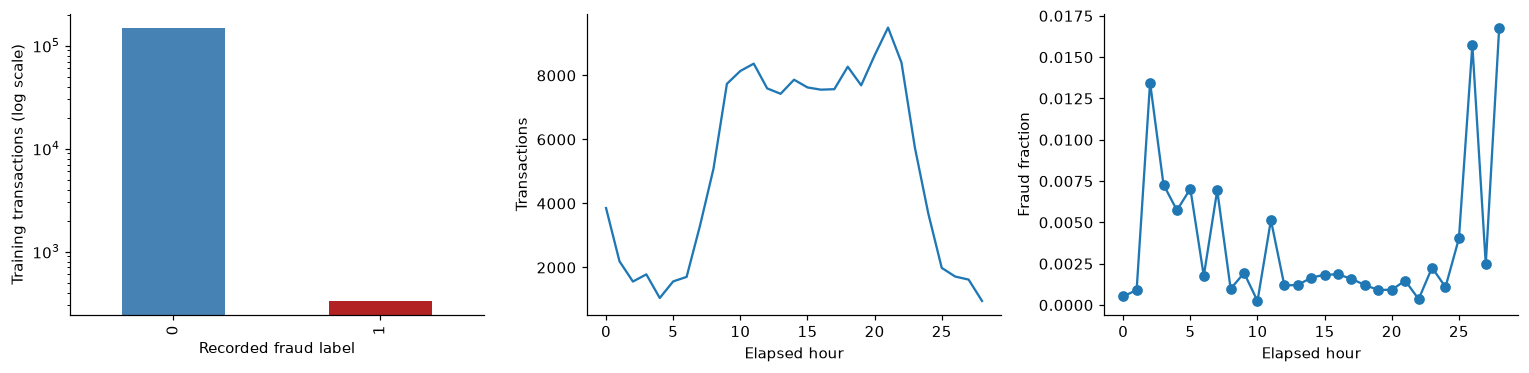

,transactions,frauds,fraud_fraction
Time,,,
0,3856,2,0.00052
1,2193,2,0.00091
2,1560,21,0.01346
3,1784,13,0.00729
4,1046,6,0.00574
5,1564,11,0.00703
6,1705,3,0.00176
7,3311,23,0.00695
8,5084,5,0.00098


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14,3.5))
train.Class.value_counts().sort_index().plot.bar(ax=ax[0], logy=True, color=['steelblue','firebrick'])
ax[0].set(xlabel='Recorded fraud label', ylabel='Training transactions (log scale)')
time_groups = train.groupby((train.Time // 3600).astype(int)).Class.agg(['size','sum','mean'])
ax[1].plot(time_groups.index, time_groups['size']); ax[1].set(xlabel='Elapsed hour', ylabel='Transactions')
ax[2].plot(time_groups.index, time_groups['mean'], marker='o'); ax[2].set(xlabel='Elapsed hour', ylabel='Fraud fraction')
plt.tight_layout(); plt.show()
display(time_groups.rename(columns={'size':'transactions','sum':'frauds','mean':'fraud_fraction'}).round(5))


## Amounts and anonymized features

Zero amounts are retained because the original source permits them. `log1p(Amount)` is used only for visualization; models receive original amounts and fold-local scaling where applicable. PCA components can retain tails, outliers, and outcome associations even when their original meanings are hidden. We examine every component, then summarize training class differences and correlation. No causal interpretation is assigned to a component.

,count,mean,std,min,1%,50%,99%,max
V1,150174.0,-0.261307,1.839349,-56.407510,-6.674205,-0.303147,2.017288,2.401777
V2,150174.0,0.042778,1.636645,-72.715728,-4.997837,0.118140,3.942191,22.057729
V3,150174.0,0.616786,1.329724,-33.680984,-3.353576,0.718792,2.870191,9.382558
V4,150174.0,0.136059,1.362111,-5.519697,-2.959152,0.148975,3.685231,16.875344
V5,150174.0,-0.242932,1.329003,-42.147898,-3.347536,-0.277044,3.060136,34.801666
V6,150174.0,0.056480,1.272429,-26.160506,-2.089819,-0.185260,4.164868,22.529298
V7,150174.0,-0.096752,1.212164,-43.557242,-3.211916,-0.045011,2.418437,36.677268
V8,150174.0,0.044484,1.241416,-73.216718,-4.063591,0.071407,2.144073,20.007208
V9,150174.0,-0.029090,1.140220,-13.434066,-2.484271,-0.120730,3.096055,15.594995
V10,150174.0,-0.028173,1.090003,-24.588262,-2.159169,-0.107663,3.246323,23.745136


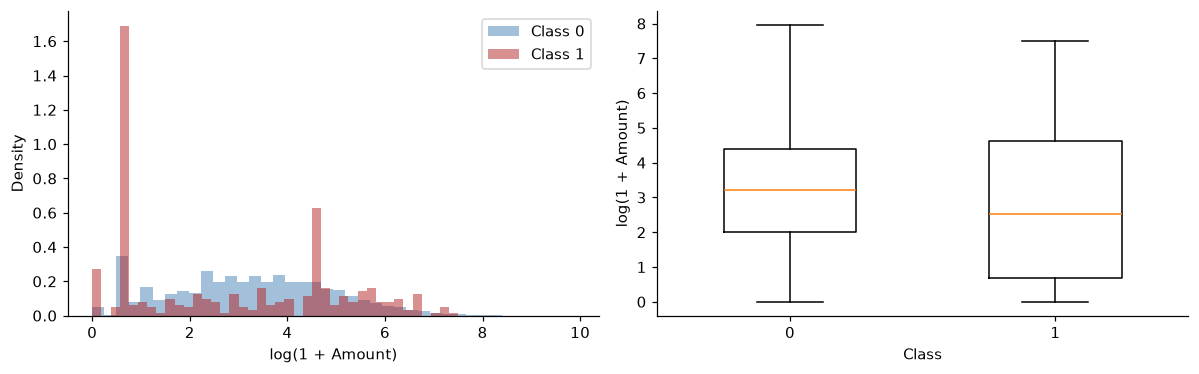

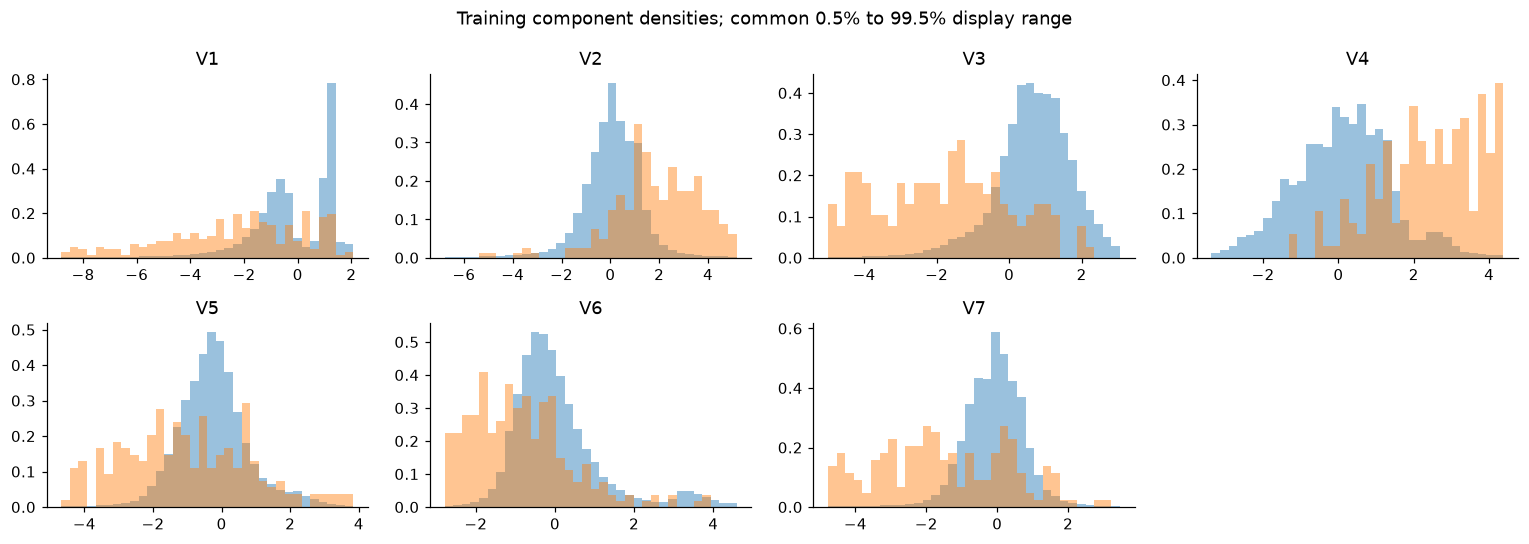

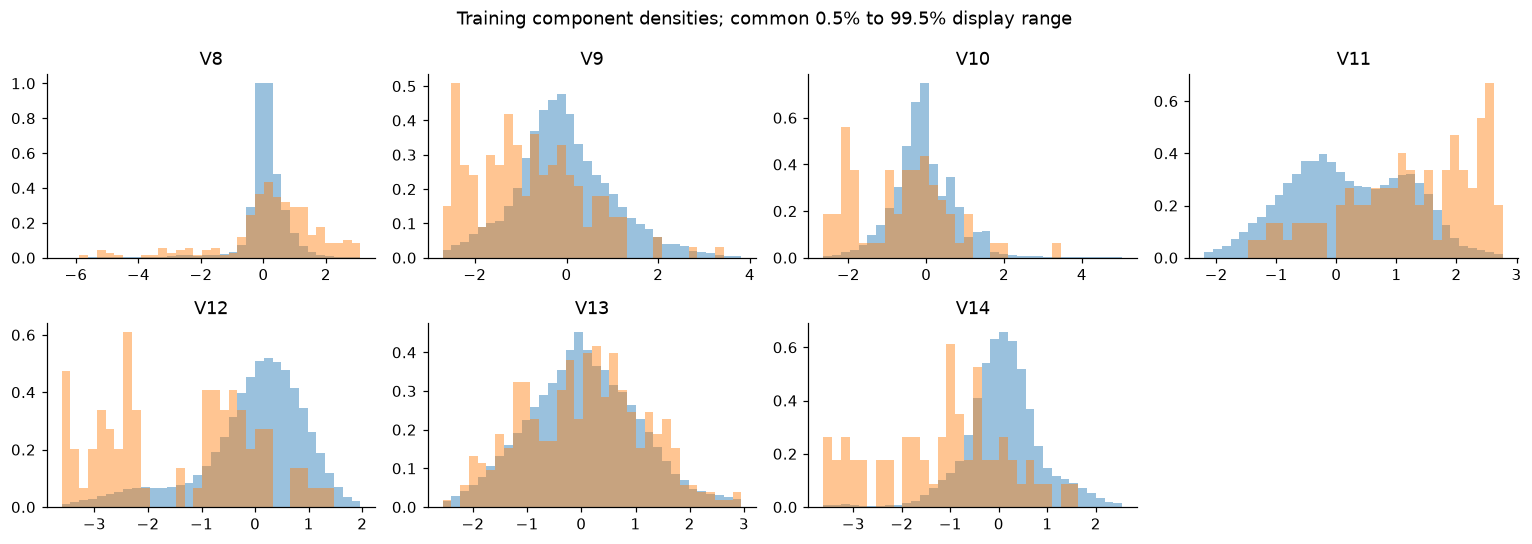

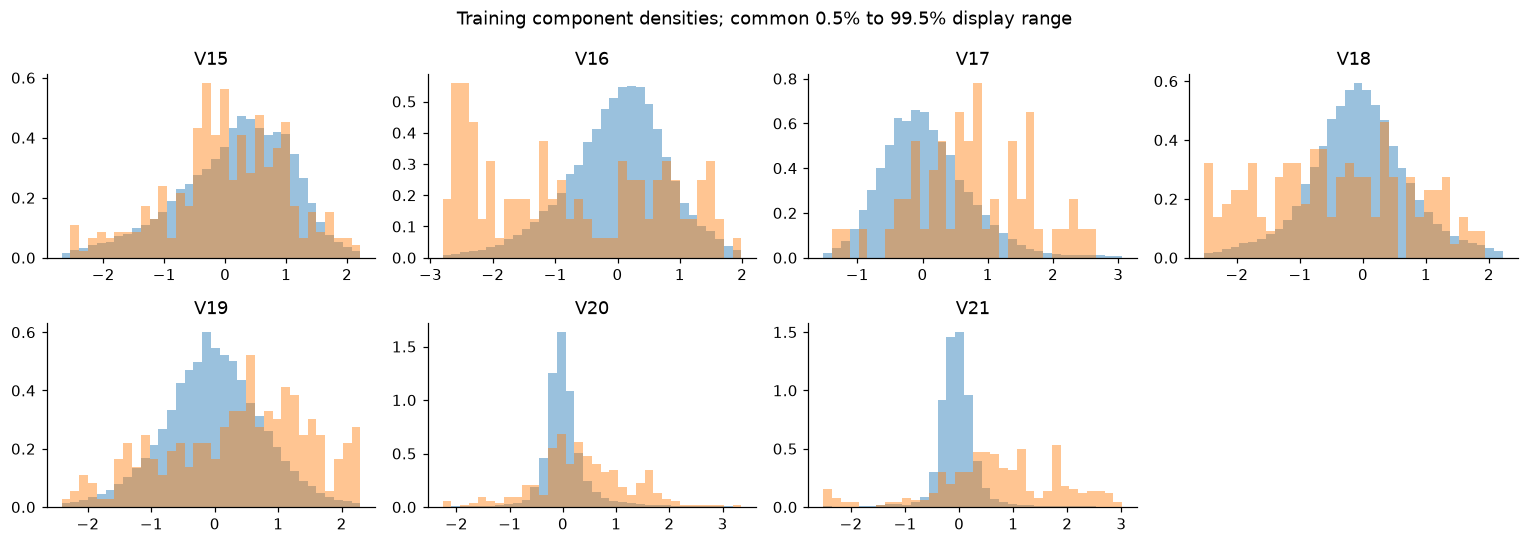

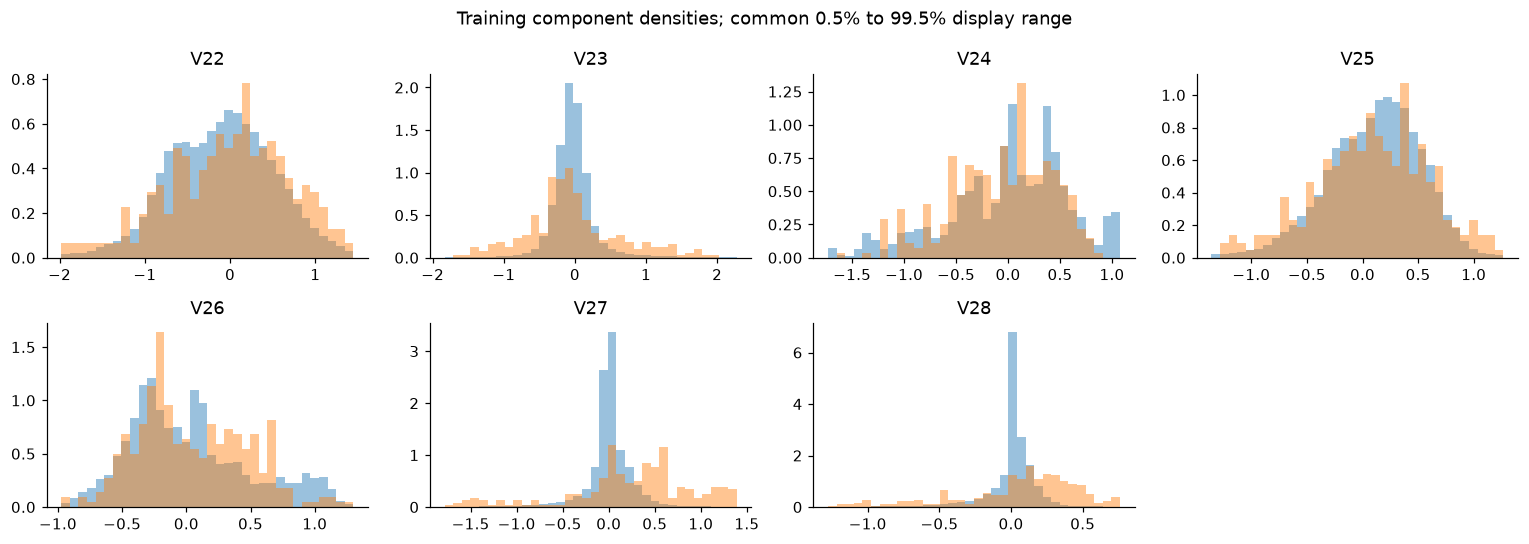

In [4]:
display(train[FEATURES].describe(percentiles=[.01,.5,.99]).T)
fig, ax = plt.subplots(1,2,figsize=(11,3.5))
for label,color in [(0,'steelblue'),(1,'firebrick')]:
 values = np.log1p(train.loc[train.Class==label,'Amount'])
 ax[0].hist(values,bins=40,density=True,alpha=.5,label=f'Class {label}',color=color)
 ax[1].boxplot(values,positions=[label],showfliers=False,widths=.5)
ax[0].set(xlabel='log(1 + Amount)',ylabel='Density'); ax[0].legend()
ax[1].set(xlabel='Class',ylabel='log(1 + Amount)',xticks=[0,1])
plt.tight_layout(); plt.show()
for start in range(1,29,7):
 fig, axes = plt.subplots(2,4,figsize=(14,5))
 for ax, component in zip(axes.flat,[f'V{i}' for i in range(start,min(start+7,29))]):
  lo,hi=train[component].quantile([.005,.995])
  for label in [0,1]:
   ax.hist(train.loc[train.Class==label,component],bins=np.linspace(lo,hi,35),density=True,alpha=.45,label=str(label))
  ax.set_title(component)
 axes.flat[-1].axis('off'); fig.suptitle('Training component densities; common 0.5% to 99.5% display range')
 plt.tight_layout(); plt.show()


,standardized_class_mean_difference
V14,-2.288232
V12,-1.998301
V10,-1.756197
V16,-1.651530
V17,-1.541263
V3,-1.467948
V9,-1.365128
V18,-1.265227
V7,-1.210715
V1,-1.043750


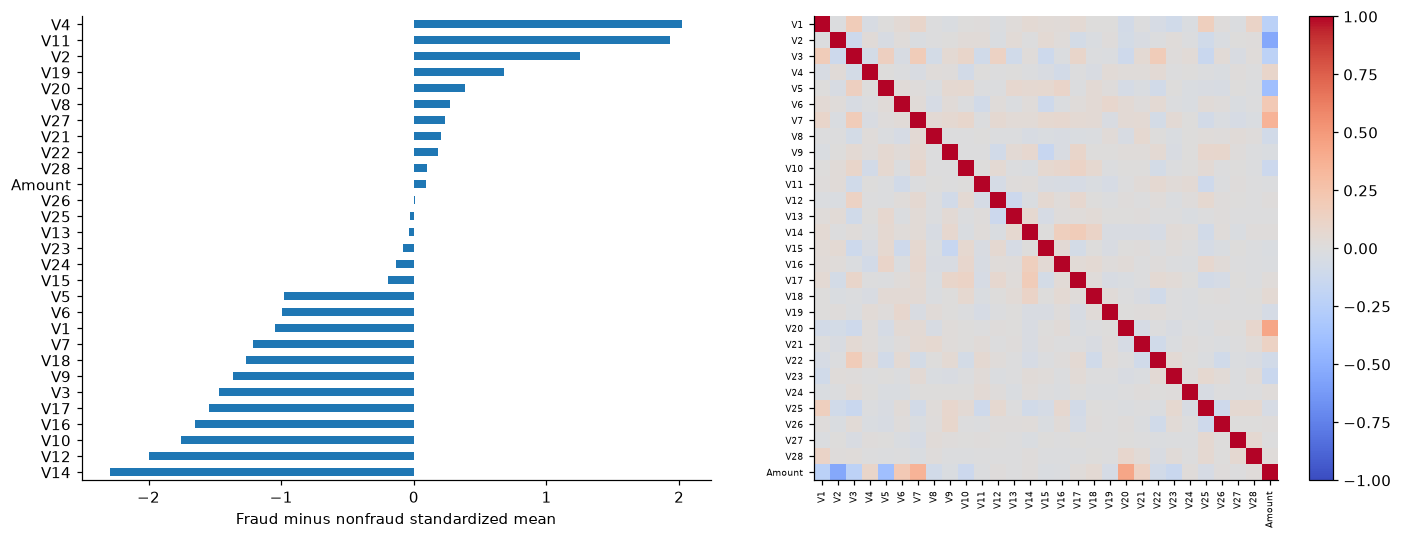

In [5]:
means=train.groupby('Class')[FEATURES].mean()
variances=train.groupby('Class')[FEATURES].var()
contrast=(means.loc[1]-means.loc[0])/np.sqrt((variances.loc[0]+variances.loc[1])/2)
display(contrast.rename('standardized_class_mean_difference').to_frame().sort_values('standardized_class_mean_difference'))
fig,ax=plt.subplots(1,2,figsize=(13,5))
contrast.sort_values().plot.barh(ax=ax[0]); ax[0].set(xlabel='Fraud minus nonfraud standardized mean')
im=ax[1].imshow(train[FEATURES].corr(),vmin=-1,vmax=1,cmap='coolwarm')
ax[1].set(xticks=range(len(FEATURES)),yticks=range(len(FEATURES)),xticklabels=FEATURES,yticklabels=FEATURES)
ax[1].tick_params(axis='x',labelrotation=90,labelsize=6); ax[1].tick_params(axis='y',labelsize=6)
fig.colorbar(im,ax=ax[1]); plt.tight_layout(); plt.show()


## Models and selection

The fixed candidates are a constant training-prevalence score, scaled logistic regression, class-balanced logistic regression, and histogram gradient boosting with 150 iterations and 15 leaves. Scaling is fitted on training data only. Boosting uses no early stopping so an internal random validation partition cannot cross the chronological protocol.

Validation AP selects the model, with insertion order resolving exact ties toward simpler candidates. Each candidate gets its own validation F1 threshold; ties favor the higher threshold. This uses the same validation cohort for model and threshold selection and may overfit it. No test outcome selects hyperparameters, a threshold, or a replacement model. All candidate test comparisons below are diagnostic comparisons of the predeclared set.

,training_AP,validation_AP
prior,0.002204,0.000821
logistic,0.769738,0.51861
balanced_logistic,0.732562,0.735804
histogram_boosting,0.187702,0.105091


,average_precision,roc_auc,brier_score,precision,recall,f1,alert_rate,threshold
prior,0.000821,0.5,0.000822,0.000821,1.0,0.001641,1.0,0.002204
logistic,0.51861,0.957907,0.000639,0.574468,0.6,0.586957,0.000857,0.276801
balanced_logistic,0.735804,0.97548,0.042492,0.868421,0.733333,0.795181,0.000693,0.999992
histogram_boosting,0.105091,0.588677,0.000781,0.615385,0.177778,0.275862,0.000237,0.104476


Validation-selected model: balanced_logistic threshold: 0.9999916589343854


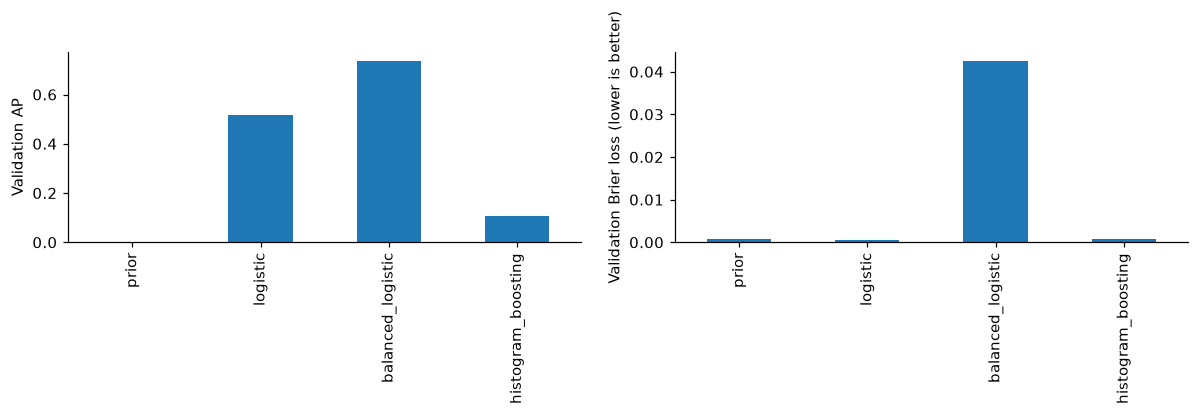

In [6]:
with threadpool_limits(limits=4):
 result, fitted_splits, models, test_scores = experiment(frame, SEED)
validation_table=pd.DataFrame(result['validation']).T
winner=result['selected_model']
threshold=result['validation'][winner]['threshold']
training_ap={name: average_precision_score(train.Class,model.predict_proba(train[FEATURES])[:,1]) for name,model in models.items()}
display(pd.DataFrame({'training_AP':training_ap,'validation_AP':validation_table.average_precision}))
display(validation_table[['average_precision','roc_auc','brier_score','precision','recall','f1','alert_rate','threshold']])
print('Validation-selected model:',winner,'threshold:',threshold)
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
validation_table.average_precision.plot.bar(ax=ax[0]); ax[0].set_ylabel('Validation AP')
validation_table.brier_score.plot.bar(ax=ax[1]); ax[1].set_ylabel('Validation Brier loss (lower is better)')
plt.tight_layout(); plt.show()


## Validation feature sensitivity

Logistic coefficients describe conditional associations after standardization. Permutation importance measures the AP loss when one validation feature is shuffled, with the model frozen. It uses a fixed validation sample of at most 10,000 records for bounded runtime and three shuffles per feature. Correlated predictors can share or conceal importance. The small validation fraud count makes permutation estimates unstable; shuffle standard deviations exclude sampling uncertainty. Neither analysis reveals the private meanings of the PCA components.

Permutation sample records: 10000 frauds: 8


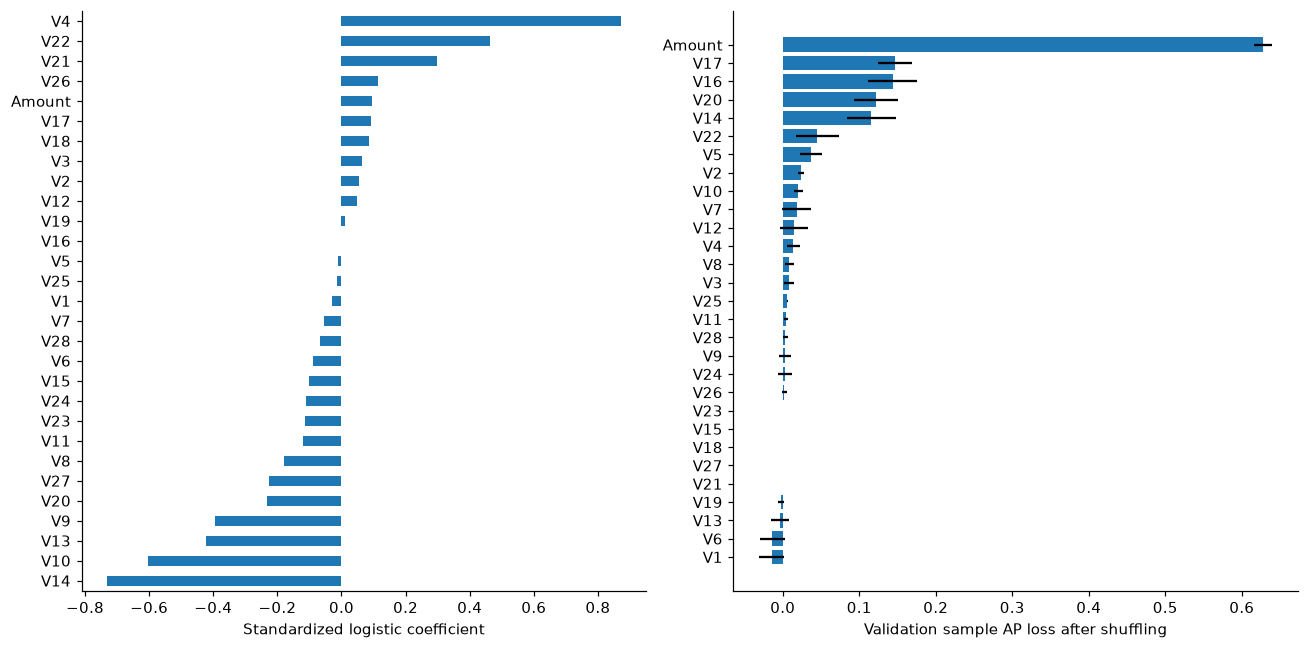

,feature,ap_loss,shuffle_sd
6,V7,0.018210,0.019078
9,V10,0.020529,0.006381
1,V2,0.023529,0.003870
4,V5,0.036956,0.013798
21,V22,0.045423,0.027657
13,V14,0.115858,0.032456
19,V20,0.121985,0.028639
15,V16,0.143812,0.031966
16,V17,0.146331,0.022079
28,Amount,0.628121,0.011779


In [7]:
coeff=pd.Series(models['logistic'][-1].coef_[0],index=FEATURES)
subset=valid.sample(n=min(10000,len(valid)),random_state=2026)
print('Permutation sample records:',len(subset),'frauds:',int(subset.Class.sum()))
with threadpool_limits(limits=4):
 importance=permutation_importance(models[winner],subset[FEATURES],subset.Class,
    scoring='average_precision',n_repeats=3,random_state=2026,n_jobs=1)
importance_table=pd.DataFrame({'feature':FEATURES,'ap_loss':importance.importances_mean,
                              'shuffle_sd':importance.importances_std}).sort_values('ap_loss')
fig,ax=plt.subplots(1,2,figsize=(12,6))
coeff.sort_values().plot.barh(ax=ax[0]); ax[0].set_xlabel('Standardized logistic coefficient')
ax[1].barh(importance_table.feature,importance_table.ap_loss,xerr=importance_table.shuffle_sd)
ax[1].set_xlabel('Validation sample AP loss after shuffling')
plt.tight_layout(); plt.show()
display(importance_table.tail(10))


## Withheld-period ranking and decisions

The table reports AP and ROC-AUC together with threshold-specific precision, recall, alert rate, and confusion counts. A high ROC-AUC can coexist with a costly review queue under severe imbalance. The PR plot uses the full linear recall range. Every candidate retains its validation threshold.

,average_precision,roc_auc,brier_score,precision,recall,f1,alert_rate,confusion
prior,0.001372,0.5,0.001371,0.001372,1.0,0.002741,1.0,"{'tn': 0, 'fp': 70581, 'fn': 0, 'tp': 97}"
logistic,0.640964,0.971417,0.00081,0.681319,0.639175,0.659574,0.001288,"{'tn': 70552, 'fp': 29, 'fn': 35, 'tp': 62}"
balanced_logistic,0.76054,0.977691,0.036272,0.956522,0.680412,0.795181,0.000976,"{'tn': 70578, 'fp': 3, 'fn': 31, 'tp': 66}"
histogram_boosting,0.109533,0.613035,0.001457,0.44,0.226804,0.29932,0.000707,"{'tn': 70553, 'fp': 28, 'fn': 75, 'tp': 22}"


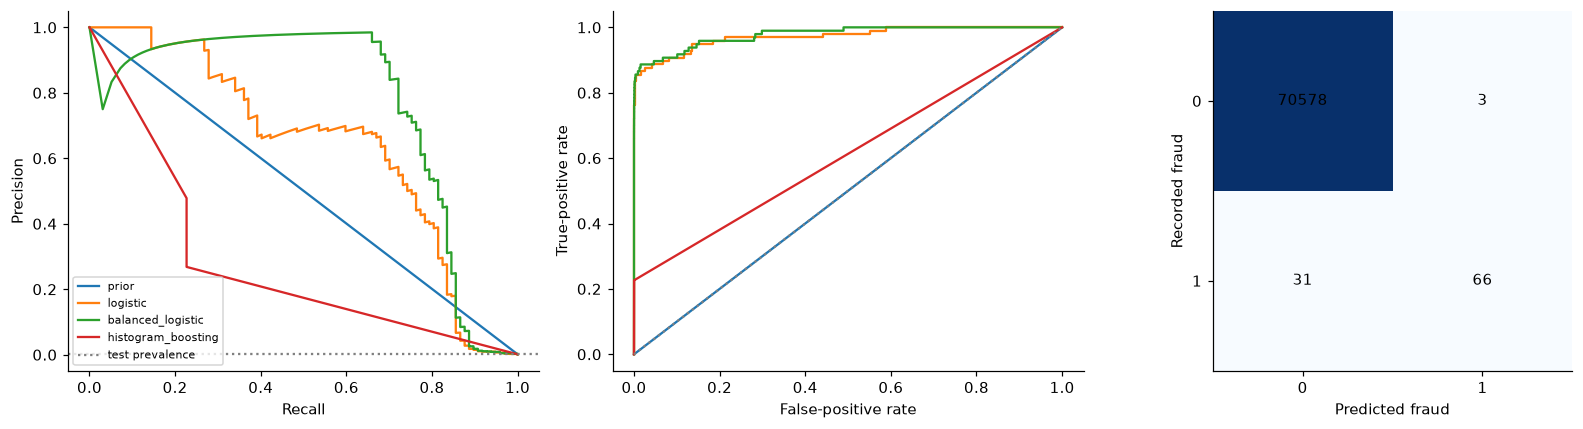

In [8]:
test_table=pd.DataFrame(result['test']).T
display(test_table[['average_precision','roc_auc','brier_score','precision','recall','f1','alert_rate','confusion']])
y=test.Class.to_numpy(); score=test_scores[winner]
fig,ax=plt.subplots(1,3,figsize=(15,4))
for name,values in test_scores.items():
 p,r,_=precision_recall_curve(y,values); ax[0].plot(r,p,label=name)
 fpr,tpr,_=roc_curve(y,values); ax[1].plot(fpr,tpr,label=name)
ax[0].axhline(y.mean(),color='gray',ls=':',label='test prevalence')
ax[0].set(xlabel='Recall',ylabel='Precision'); ax[0].legend(fontsize=7)
ax[1].plot([0,1],[0,1],color='gray',ls=':'); ax[1].set(xlabel='False-positive rate',ylabel='True-positive rate')
cm=confusion_matrix(y,score>=threshold,labels=[0,1]); ax[2].imshow(cm,cmap='Blues')
for (i,j),value in np.ndenumerate(cm): ax[2].text(j,i,str(value),ha='center',va='center')
ax[2].set(xticks=[0,1],yticks=[0,1],xlabel='Predicted fraud',ylabel='Recorded fraud')
plt.tight_layout(); plt.show()


## Calibration and rare-event probability quality

A class-balanced loss changes the effective class prior during fitting. Its output need not estimate the observed fraud probability. Reliability diagrams compare average score with observed fractions in quantile bins; bins combine many low scores under this imbalance. They are descriptive, and no recalibration is fitted on the withheld cohort. Brier score and log loss should be compared with the constant prior, whose predictions can be accurate on average while ranking no transaction usefully.

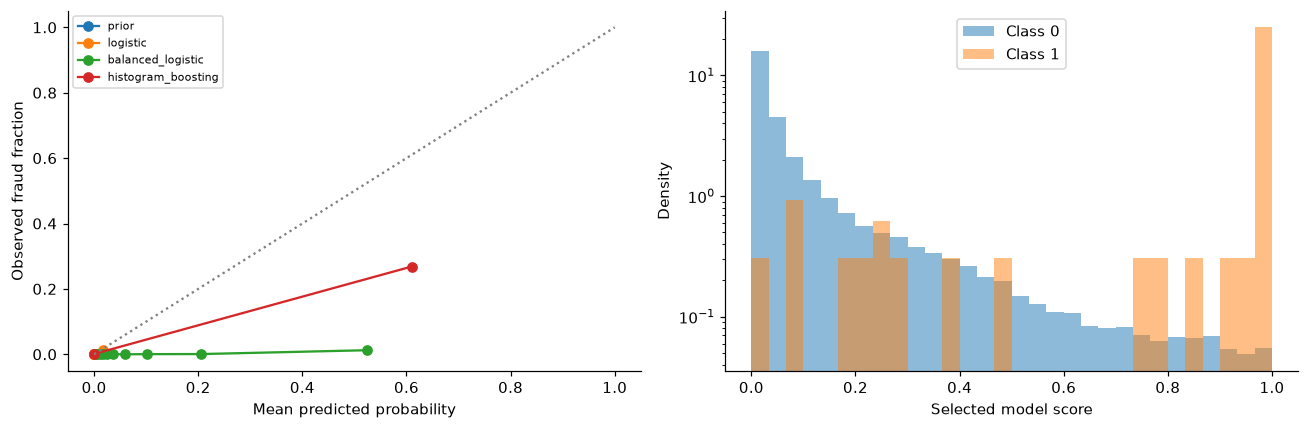

,brier_score,log_loss,expected_calibration_error
prior,0.001371,0.010599,0.000832
logistic,0.00081,0.004134,0.000843
balanced_logistic,0.036272,0.141867,0.097511
histogram_boosting,0.001457,0.05182,0.001457


In [9]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for name,values in test_scores.items():
 observed,predicted=calibration_curve(y,values,n_bins=10,strategy='quantile')
 ax[0].plot(predicted,observed,marker='o',label=name)
ax[0].plot([0,1],[0,1],ls=':',color='gray'); ax[0].set(xlabel='Mean predicted probability',ylabel='Observed fraud fraction'); ax[0].legend(fontsize=7)
for label in [0,1]: ax[1].hist(score[y==label],bins=np.linspace(0,1,31),density=True,alpha=.5,label=f'Class {label}')
ax[1].set(xlabel='Selected model score',ylabel='Density',yscale='log'); ax[1].legend()
plt.tight_layout(); plt.show()
display(test_table[['brier_score','log_loss','expected_calibration_error']])


## Review capacity and threshold transfer

The primary threshold maximizes validation F1, which weights precision and recall equally and embeds no financial cost model. Additional operating points target validation alert fractions of 0.1%, 0.5%, 1%, 2%, and 5%. Their cutoffs are selected exclusively from validation scores and then carried into test. Ties can exceed the nominal budget. Test alert fractions can differ because the score distribution changes. A fixed review capacity in production would need a separately specified queue policy.

,validation_budget,threshold,precision,recall,alert_rate,alerts,false_alerts
0,0.001,0.999958,0.760870,0.721649,0.001302,92,22
1,0.005,0.940183,0.275168,0.845361,0.004216,298,216
2,0.010,0.861633,0.127496,0.855670,0.009211,651,568
3,0.020,0.733525,0.068745,0.886598,0.017700,1251,1165
4,0.050,0.507200,0.029625,0.886598,0.041074,2903,2817


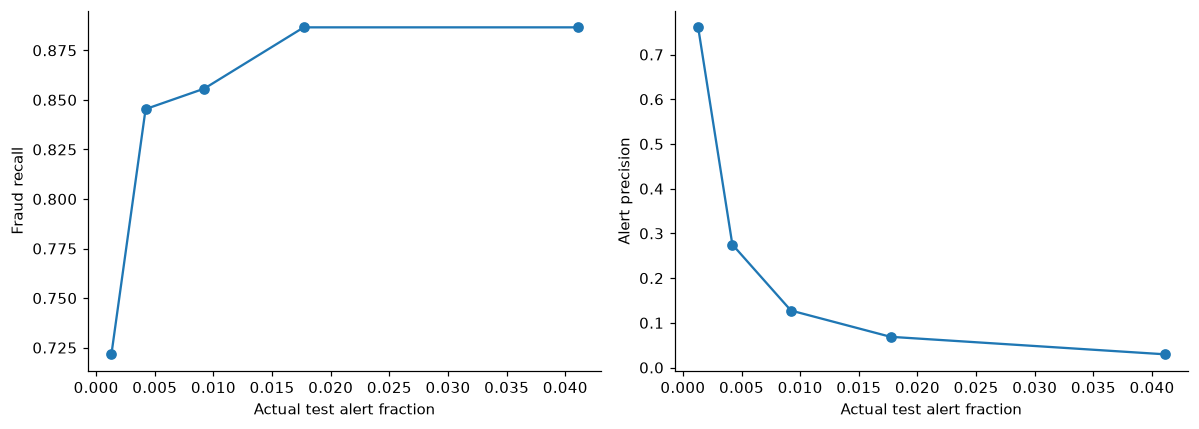

In [10]:
validation_score=models[winner].predict_proba(valid[FEATURES])[:,1]
operating=[]
for budget in [.001,.005,.01,.02,.05]:
 cutoff=float(np.quantile(validation_score,1-budget))
 row=summarize(y,score,cutoff)
 operating.append({'validation_budget':budget,'threshold':cutoff,**{k:row[k] for k in ['precision','recall','alert_rate']},
                   'alerts':int((score>=cutoff).sum()),'false_alerts':row['confusion']['fp']})
operating=pd.DataFrame(operating); display(operating)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(operating.alert_rate,operating.recall,marker='o'); ax[0].set(xlabel='Actual test alert fraction',ylabel='Fraud recall')
ax[1].plot(operating.alert_rate,operating.precision,marker='o'); ax[1].set(xlabel='Actual test alert fraction',ylabel='Alert precision')
plt.tight_layout(); plt.show()


## Errors across amounts and elapsed time

Amounts are grouped using training quartiles, and time groups use two-hour elapsed intervals. These aggregate profiles identify where false alerts and missed fraud accumulate. They do not reveal individual records. Small fraud counts make subgroup rates unstable; a zero observed error rate does not establish zero risk. The grouping rules were fixed without inspecting test errors.

,field,group,rows,frauds,fp,fn,fpr,fnr
0,amount,"(-inf, 6.49]",18775,50,0,13,0.000000,0.260000
1,amount,"(6.49, 24.0]",18215,12,0,7,0.000000,0.583333
2,amount,"(24.0, 80.0]",17218,9,0,4,0.000000,0.444444
3,amount,"(80.0, inf]",16470,26,3,7,0.000182,0.269231
4,elapsed_2h,19,13326,21,0,6,0.000000,0.285714
5,elapsed_2h,20,16315,24,2,6,0.000123,0.250000
6,elapsed_2h,21,15439,30,0,10,0.000000,0.333333
7,elapsed_2h,22,14831,12,0,3,0.000000,0.250000
8,elapsed_2h,23,10767,10,1,6,0.000093,0.600000


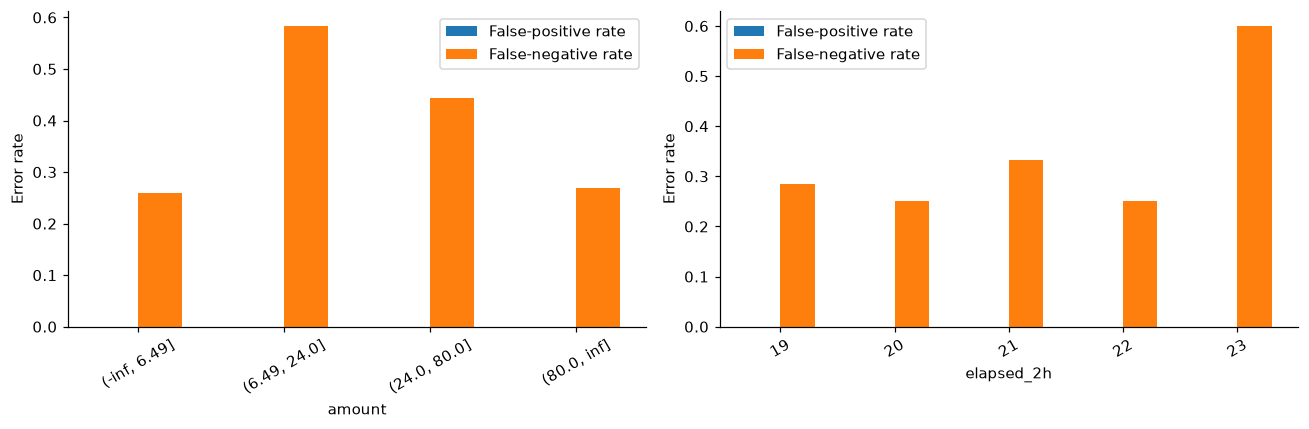

In [11]:
edges=np.r_[-np.inf,np.unique(train.Amount.quantile([.25,.5,.75]).to_numpy()),np.inf]
amount_group=pd.cut(test.Amount,edges).astype(str)
error_rows=[]
for field,groups in [('amount',amount_group),('elapsed_2h',(test.Time//7200).astype(int).astype(str))]:
 for group in (list(pd.cut(test.Amount,edges).cat.categories.astype(str)) if field=='amount' else sorted(groups.unique())):
  mask=(groups==group).to_numpy(); yy=y[mask]; alerts=score[mask]>=threshold
  tn,fp,fn,tp=confusion_matrix(yy,alerts,labels=[0,1]).ravel()
  error_rows.append({'field':field,'group':group,'rows':int(mask.sum()),'frauds':int(yy.sum()),
                     'fp':int(fp),'fn':int(fn),'fpr':fp/max(fp+tn,1),'fnr':fn/max(fn+tp,1)})
errors=pd.DataFrame(error_rows); display(errors)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for axis,field in zip(ax,['amount','elapsed_2h']):
 part=errors[errors.field==field]; x=np.arange(len(part))
 axis.bar(x-.15,part.fpr,width=.3,label='False-positive rate'); axis.bar(x+.15,part.fnr,width=.3,label='False-negative rate')
 axis.set(xticks=x,xticklabels=part.group,xlabel=field,ylabel='Error rate'); axis.tick_params(axis='x',rotation=30); axis.legend()
plt.tight_layout(); plt.show()


## Uncertainty conditional on the frozen experiment

Two hundred bootstrap resamples draw 30-minute test blocks with replacement, retaining each block's transactions together. This acknowledges some local time dependence; it cannot preserve unknown cardholder dependence. Resamples without both classes are skipped and counted. Percentile intervals condition on the selected model, cutoff, available two-day cohort, and block definition. They exclude model-training and selection uncertainty and do not establish future performance.

,estimate,lower_95,upper_95
average_precision,0.760540,0.656239,0.860407
roc_auc,0.977691,0.964508,0.990169
brier_score,0.036272,0.034944,0.037646
precision,0.956522,0.919866,0.987662
recall,0.680412,0.599908,0.757903


Completed resamples: 200 skipped: 0 time blocks: 20


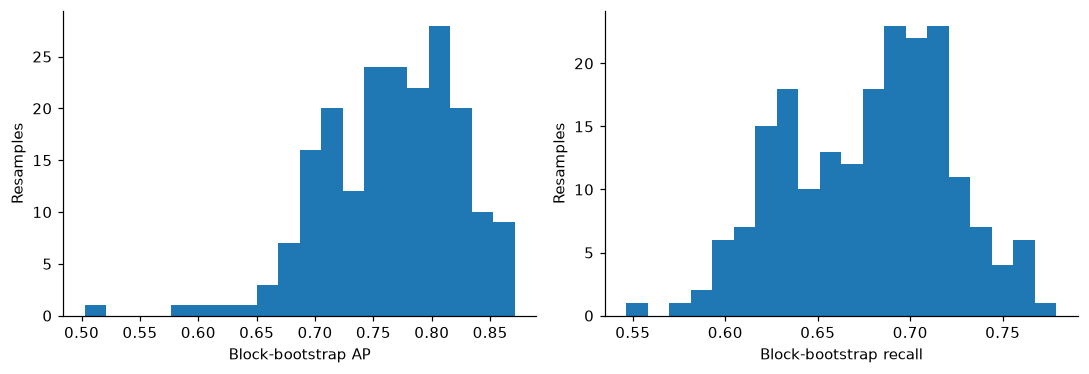

In [12]:
blocks=(test.Time.to_numpy()//1800).astype(int)
block_indices=[np.flatnonzero(blocks==b) for b in np.unique(blocks)]
rng=np.random.default_rng(2026); draws=[]; skipped=0
for _ in range(200):
 ids=np.concatenate([block_indices[i] for i in rng.integers(0,len(block_indices),len(block_indices))])
 yy=y[ids]; ss=score[ids]
 if len(np.unique(yy))<2: skipped+=1; continue
 alerts=ss>=threshold; tn,fp,fn,tp=confusion_matrix(yy,alerts,labels=[0,1]).ravel()
 draws.append({'average_precision':average_precision_score(yy,ss),'roc_auc':roc_auc_score(yy,ss),
  'brier_score':brier_score_loss(yy,ss),'precision':tp/max(tp+fp,1),'recall':tp/max(tp+fn,1)})
draws=pd.DataFrame(draws)
intervals=pd.DataFrame({'estimate':{k:result['test'][winner][k] for k in draws.columns},
                        'lower_95':draws.quantile(.025),'upper_95':draws.quantile(.975)})
display(intervals); print('Completed resamples:',len(draws),'skipped:',skipped,'time blocks:',len(block_indices))
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].hist(draws.average_precision,bins=20); ax[0].set(xlabel='Block-bootstrap AP',ylabel='Resamples')
ax[1].hist(draws.recall,bins=20); ax[1].set(xlabel='Block-bootstrap recall',ylabel='Resamples')
plt.tight_layout(); plt.show()


## Findings and limitations

Balanced logistic regression leads validation AP at 0.735804, compared with 0.518610 for unweighted logistic regression and 0.105091 for histogram boosting. Histogram boosting also has low training AP (0.187702), so the poor validation ranking is not explained solely by a strong training fit followed by collapse. This fixed configuration warrants a separate tuning study.

On the withheld period, balanced logistic regression AP is 0.760540 (30-minute block-bootstrap 95% interval 0.656239 to 0.860407) and ROC-AUC is 0.977691. These intervals are conditional on this frozen experiment.

The validation cutoff is approximately 0.999992, reflecting the strongly distorted balanced-loss probability scale. The selected cutoff flags 69 of 70,678 withheld transactions: 66 recorded frauds and 3 false alerts, with 31 frauds missed. Precision is 0.956522 and recall is 0.680412. The unusually small false-alert count should be read alongside the short test window, anonymized features, and only 97 retained test frauds.

Ranking and probability estimation give different conclusions. Balanced logistic regression has test Brier loss 0.036272, much worse than the constant prior's 0.001371 and unweighted logistic regression's 0.000810. Class balancing produces useful ranking here but substantially overstates event probabilities. The 0.5 cutoff is not used, and scores should not be treated as calibrated monetary-risk estimates.

The raw cohort has 284,807 rows and 492 fraud labels. Removing 9,144 later exact predictor repeats leaves 275,663 rows and 473 frauds. Training, validation, and test contain 150,174 / 54,811 / 70,678 transactions and 331 / 45 / 97 frauds. This filter changes the evaluation population. Results should not be compared as if they used all original rows or a random split.

The next cell states results directly from the completed experiment. The winner is the validation-selected candidate even if another method appears stronger on test. Fraud recovery and review workload must be read together. Captured fraud labels do not measure money recovered, false-alert harm, prevented fraud, or the effects of an investigator's actions.

This is an internal chronological benchmark on two historical days. Unknown label delay, upstream PCA fitting, unidentified repeated cardholders, exact-repeat filtering, and changing fraud practices limit its interpretation. A deployment study needs longer periods, authorization-time feature availability, matured labels, investigation capacity, and external validation. No clinical, creditworthiness, or operational safety claim follows from these results.

In [13]:
r=result['test'][winner]
print(f"Selected {winner}; test AP {r['average_precision']:.6f}, ROC-AUC {r['roc_auc']:.6f}.")
print(f"At validation threshold {threshold:.6f}: precision {r['precision']:.4f}, recall {r['recall']:.4f}, alert fraction {r['alert_rate']:.4f}.")
print('Test confusion counts:',r['confusion'])
print(f"Constant-prior test Brier: {result['test']['prior']['brier_score']:.6f}; selected-model Brier: {r['brier_score']:.6f}.")
result['input_sha256']=manifest['sha256']; result['environment']=environment
result['bootstrap']={'replicates':len(draws),'skipped':skipped,'block_seconds':1800,'intervals':intervals.to_dict()}
result['elapsed_seconds']=time.monotonic()-started
out=ROOT/'artifacts/research'; out.mkdir(parents=True,exist_ok=True)
(out/'aggregate_results.json').write_text(json.dumps(result,indent=2,allow_nan=False),encoding='utf-8')
print('Aggregate experiment completed in seconds:',round(result['elapsed_seconds'],1))


Selected balanced_logistic; test AP 0.760540, ROC-AUC 0.977691.
At validation threshold 0.999992: precision 0.9565, recall 0.6804, alert fraction 0.0010.
Test confusion counts: {'tn': 70578, 'fp': 3, 'fn': 31, 'tp': 66}
Constant-prior test Brier: 0.001371; selected-model Brier: 0.036272.
Aggregate experiment completed in seconds: 22.9


## Reproducibility

Run this notebook from a fresh Python kernel after obtaining the checksum-verified Parquet at `data/creditcard.parquet` and its retrieval manifest. The environment and package versions are printed above. Computation is limited to four numerical threads during model fitting. Seed 42 fixes candidate randomness; seed 2026 fixes permutation sampling and bootstrap resampling. The reusable `transaction_anomaly.creditcard` module supplies the original-field adapter and frozen experiment protocol, with separate contract tests. Local artifacts contain aggregate results only; the notebook retains no individual prediction table or model object.